# Sizing a field, and checking the answer

A simulation tells you what a given field does. The Sizing tool of GHE Analysis goes the other way and computes how
long the field should be for given loads. This notebook runs it, breaks its answer down to show
where the length comes from, varies the inputs, and compares the result with simulations, since the
two tools use different methods.

The figures follow GHE Analysis: red for heating and blue for cooling, as in the application. The project is the office building of the [first notebook](01_simulation.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pyghe as ga
import ghestyle as ghe
from demo_project import make_project

ghe.use()          # the colours, fonts and axis style of GHE Analysis

## One call

`size()` runs the three-pulse method. A yearly pulse, a monthly pulse and an hourly peak are
superposed, each with the thermal response of the ground over its duration, and the length follows
from the temperature the fluid may reach. It returns a length for each mode, and the longer one
governs.

In [2]:
p = make_project()
s = p.size()
print("governing mode:", s.governing_mode)
print(f"governing total borehole length: {s.governing_total_borehole_length:.0f} m")
print(f"installed in the project:        {12 * p.ground_heat_exchanger.active_length:.0f} m")

governing mode: heating
governing total borehole length: 1013 m
installed in the project:        1200 m


The result holds every quantity of the Sizing tool, as a heating value and a cooling value:

In [3]:
table = pd.DataFrame({
    "heating": [s.yearly_ground_load.heating, s.monthly_ground_load.heating, s.hourly_ground_load.heating,
                s.yearly_response_factor.heating, s.monthly_response_factor.heating,
                s.hourly_peak_response_factor.heating, s.effective_borehole_resistance.heating,
                s.undisturbed_ground_temperature.heating, s.mean_fluid_temperature.heating,
                s.total_borehole_length.heating],
    "cooling": [s.yearly_ground_load.cooling, s.monthly_ground_load.cooling, s.hourly_ground_load.cooling,
                s.yearly_response_factor.cooling, s.monthly_response_factor.cooling,
                s.hourly_peak_response_factor.cooling, s.effective_borehole_resistance.cooling,
                s.undisturbed_ground_temperature.cooling, s.mean_fluid_temperature.cooling,
                s.total_borehole_length.cooling],
}, index=["qy (kW)", "qm (kW)", "qh (kW)", "Rgy (mK/W)", "Rgm (mK/W)", "Rgh (mK/W)", "Rb* (mK/W)",
          "Tg (°C)", "Tm (°C)", "L (m)"])
table.round(3)

,heating,cooling
qy (kW),3.852,3.852
qm (kW),14.186,-11.231
qh (kW),24.200,-47.200
Rgy (mK/W),0.706,0.488
Rgm (mK/W),0.151,0.149
Rgh (mK/W),0.073,0.073
Rb* (mK/W),0.131,0.119
Tg (°C),9.061,8.439
Tm (°C),-0.609,31.179
L (m),1013.253,390.758


## Where the length comes from

The Sizing tool's formula is

    L = (qy·Rgy + qm·Rgm + qh·Rgh + qh·Rb*) / (Tg − Tm)

The three pulses are the loads on the ground over a year, a month and an hour, each multiplied by
the resistance of the ground to that pulse. The last term is the borehole itself. Divided by the
length, each term is a temperature: the part of the gap between the ground and the fluid that it
accounts for. The four add up to `Tg − Tm`, the temperature the fluid is allowed to reach. Breaking
the answer down this way shows what drives the design, and checks the result.

In [4]:
def drops(mode):
    """The four terms of the formula, in kelvin, and their sum."""
    g = lambda quantity: getattr(quantity, mode)
    length = g(s.total_borehole_length)
    terms = [g(s.yearly_ground_load) * g(s.yearly_response_factor),
             g(s.monthly_ground_load) * g(s.monthly_response_factor),
             g(s.hourly_ground_load) * g(s.hourly_peak_response_factor),
             g(s.hourly_ground_load) * g(s.effective_borehole_resistance)]
    kelvin = [1000 * t / length for t in terms]           # kW · mK/W is 1000 K·m
    return kelvin, g(s.undisturbed_ground_temperature) - g(s.mean_fluid_temperature)

heating, heating_gap = drops("heating")
cooling, cooling_gap = drops("cooling")
assert abs(sum(heating) - heating_gap) < 1e-6 and abs(sum(cooling) - cooling_gap) < 1e-6
print("Tg - Tm:", round(heating_gap, 2), "K in heating,", round(cooling_gap, 2), "K in cooling")

Tg - Tm: 9.67 K in heating, -22.74 K in cooling


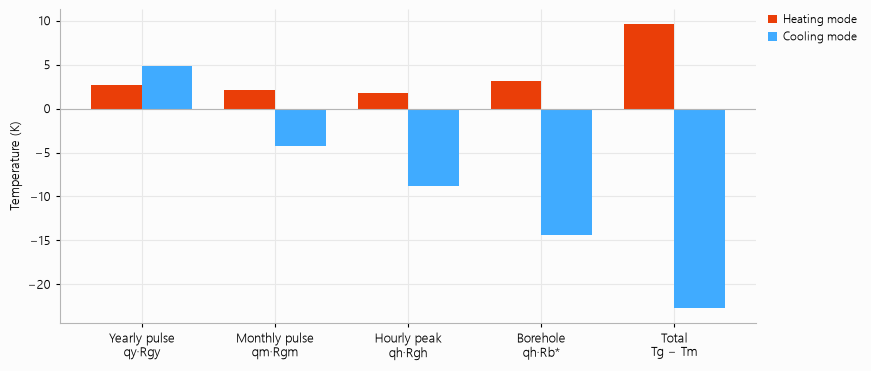

In [5]:
labels = ["Yearly pulse\nqy·Rgy", "Monthly pulse\nqm·Rgm", "Hourly peak\nqh·Rgh", "Borehole\nqh·Rb*", "Total\nTg − Tm"]
fig, ax = ghe.figure(8.6, 3.6)
ghe.mode_bars(ax, labels, heating + [heating_gap], cooling + [cooling_gap])
ghe.axis_titles(ax, y="Temperature (K)")

In heating, each pulse takes a share of the gap and the four shares add up to the total on the
right. In cooling the signs split: the yearly term is positive and the monthly and hourly ones are
negative, because the yearly net load is an extraction while the peaks are injections, and the
total is still their sum. The length is the one for which the shares fill the gap.

## How the answer moves

The Sizing tool is fast enough to vary a parameter and follow the length. `ga.sweep` does it in one
call and returns a table. I start with the ground conductivity, the parameter the design is most
sensitive to and one that a thermal response test gives only within a tolerance:

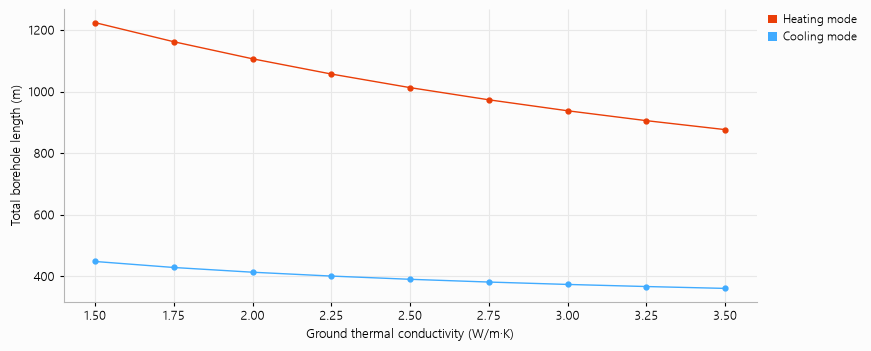

In [6]:
conductivity = np.linspace(1.5, 3.5, 9)
study = ga.sweep(p, {"ground_heat_exchanger.ground_thermal_conductivity": conductivity}, "size")

fig, ax = ghe.figure(8.6, 3.4)
ghe.mode_lines(ax, conductivity, study["total_borehole_length_heating"], study["total_borehole_length_cooling"])
ghe.axis_titles(ax, x="Ground thermal conductivity (W/m·K)", y="Total borehole length (m)")

Heating governs over the whole range, and both lengths fall as the conductivity rises, with
diminishing returns. A poor ground costs most in heating.

The grout comes next. Better grout lowers the resistance of the borehole and the design needs fewer
metres. Two panels: the effective resistance, and what it does to the length.

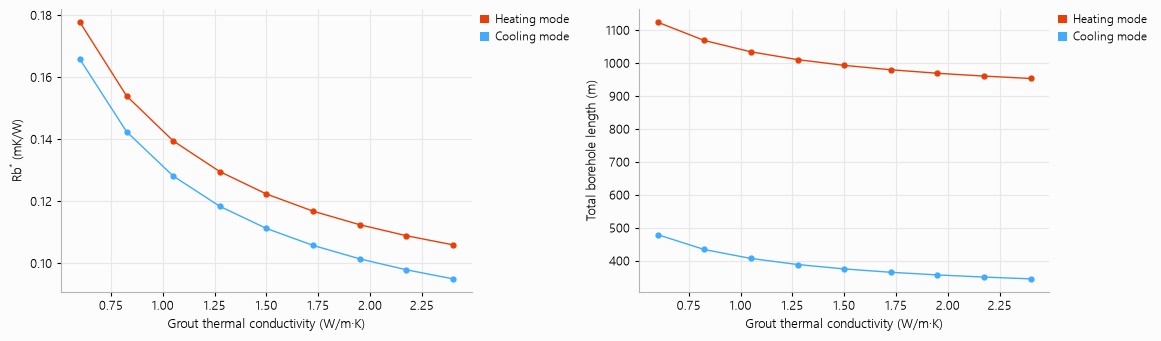

In [7]:
grout = np.linspace(0.6, 2.4, 9)
study = ga.sweep(p, {"borehole_resistance.grout_thermal_conductivity": grout}, "size")

fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 3.3))
ghe.mode_lines(left, grout, study["effective_borehole_resistance_heating"], study["effective_borehole_resistance_cooling"])
ghe.axis_titles(left, x="Grout thermal conductivity (W/m·K)", y="Rb$^{*}$ (mK/W)")
ghe.mode_lines(right, grout, study["total_borehole_length_heating"], study["total_borehole_length_cooling"])
ghe.axis_titles(right, x="Grout thermal conductivity (W/m·K)", y="Total borehole length (m)")

The method depends on the durations of its pulses, and so does the answer. The yearly pulse is a
choice of the Sizing tool: ten years is the default, standing for the long-term imbalance the field
has to absorb. In heating, a longer pulse asks for a longer field, mostly in the first few years,
and the curve flattens after that. In cooling the duration hardly matters.

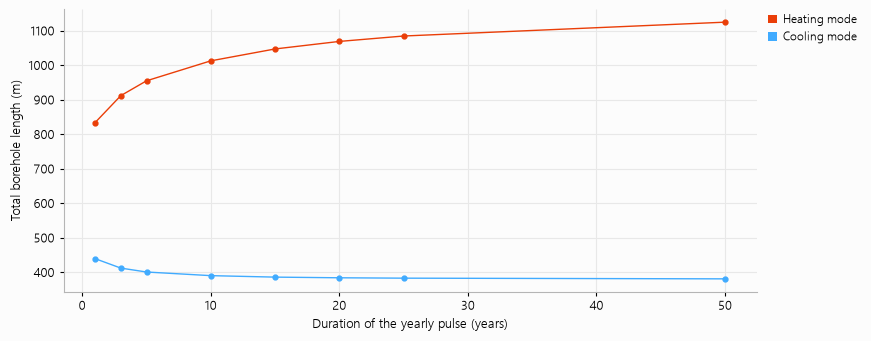

In [8]:
years = [1, 3, 5, 10, 15, 20, 25, 50]
study = ga.sweep(p, {"sizing_tool.duration_of_yearly_pulse": years}, "size")

fig, ax = ghe.figure(8.6, 3.3)
ghe.mode_lines(ax, years, study["total_borehole_length_heating"], study["total_borehole_length_cooling"])
ghe.axis_titles(ax, x="Duration of the yearly pulse (years)", y="Total borehole length (m)")

The hourly peak pulse takes two values, 1 hour or 6 hours. The longer pulse is the more
conservative: here it asks for a few per cent more length in heating and about a fifth more in
cooling.

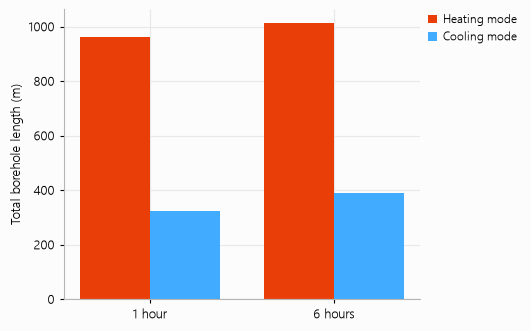

In [9]:
study = ga.sweep(p, {"sizing_tool.duration_of_hourly_peak_pulse": [1, 6]}, "size")

fig, ax = ghe.figure(5.2, 3.2)
ghe.mode_bars(ax, ["1 hour", "6 hours"], study["total_borehole_length_heating"], study["total_borehole_length_cooling"])
ghe.axis_titles(ax, y="Total borehole length (m)")

## The shape of the field

The same twelve boreholes can be laid out in many ways, and the layout changes how much they
interfere. `run_many` runs one computation over a list of projects. Here the twelve boreholes are
in a line, in two rows, and in three rows of four at several spacings:

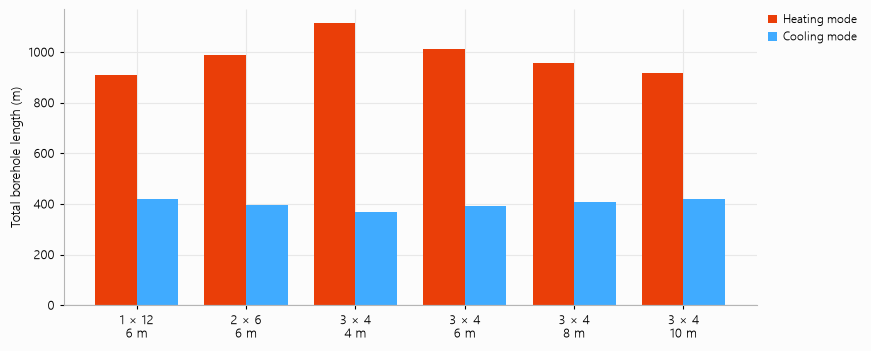

In [10]:
layouts = [("1 × 12\n6 m", 1, 12, 6.0), ("2 × 6\n6 m", 2, 6, 6.0), ("3 × 4\n4 m", 3, 4, 4.0),
           ("3 × 4\n6 m", 3, 4, 6.0), ("3 × 4\n8 m", 3, 4, 8.0), ("3 × 4\n10 m", 3, 4, 10.0)]
variants = []
for label, nx, ny, spacing in layouts:
    q = p.copy()
    q.ground_heat_exchanger.coordinates = ga.Coordinates.rectangle(nx=nx, ny=ny, spacing=spacing)
    variants.append(q)
results = ga.run_many(variants, "size")

fig, ax = ghe.figure(8.6, 3.4)
ghe.mode_bars(ax, [l[0] for l in layouts], [r.total_borehole_length.heating for r in results],
              [r.total_borehole_length.cooling for r in results])
ghe.axis_titles(ax, y="Total borehole length (m)")

In heating, the tight block asks for the most metres and the layouts that spread the boreholes out
ask for fewer. Going from 4 m to 6 m gains more than going from 8 m to 10 m, so the gain from
spacing fades quickly. In cooling the lengths move much less, and slightly the other way. These
numbers can be weighed against the cost of the land.

## Checking the answer with a simulation

The Sizing tool and the simulation are two different methods. The first superposes three pulses and
finds a length; the second runs every hour of 25 years. Here I run the second on the answer of the
first, and on lengths around it.

The twelve boreholes stay and their length changes, so that the total is a fraction of the sized
length, from 70 % to 130 %. For each, I simulate and look at the coldest entering fluid temperature
and at the number of hours the heat pumps spent below their limit.

In [11]:
sized = s.governing_total_borehole_length
fractions = [0.7, 0.85, 1.0, 1.15, 1.3]
variants = []
for fraction in fractions:
    q = p.copy()
    q.ground_heat_exchanger.active_length = fraction * sized / 12
    variants.append(q)

runs = ga.run_many(variants, "simulate")
lengths = [f * sized for f in fractions]
coldest = [r.summary.minimum_eft for r in runs]
hours_below = [r.summary.hours_below_temperature_limit for r in runs]
limit = p.heat_pump_performance.temperature_limit.heating

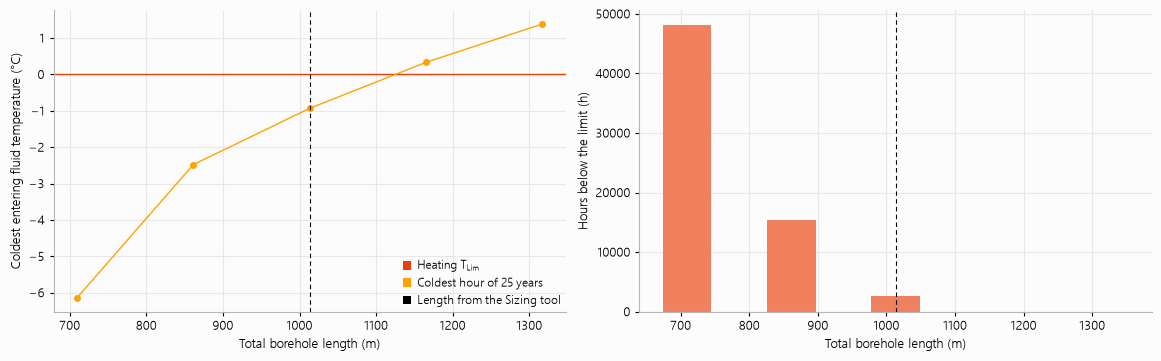

In [12]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 3.5))

left.axhline(limit, color=ghe.RED, linewidth=1.0)
left.plot(lengths, coldest, color=ghe.ORANGE, marker="o", markersize=4)
left.axvline(sized, color=ghe.BLACK, linewidth=0.8, linestyle=(0, (4, 3)))
ghe.axis_titles(left, x="Total borehole length (m)", y="Coldest entering fluid temperature (°C)")
ghe.legend(left, [(ghe.RED, "Heating T$_{Lim}$"), (ghe.ORANGE, "Coldest hour of 25 years"),
                  (ghe.BLACK, "Length from the Sizing tool")], outside=False, loc="lower right")

right.bar(lengths, hours_below, width=0.07 * sized, color=ghe.RED2)
right.axvline(sized, color=ghe.BLACK, linewidth=0.8, linestyle=(0, (4, 3)))
ghe.axis_titles(right, x="Total borehole length (m)", y="Hours below the limit (h)")

In [13]:
# The length at which the coldest hour just reaches the limit, by linear interpolation.
needed = np.interp(limit, coldest, lengths)
print(f"Sizing tool: {sized:.0f} m.  Simulation: the limit is just respected at {needed:.0f} m, "
      f"{100 * (needed / sized - 1):+.0f} % from the Sizing tool.")

Sizing tool: 1013 m.  Simulation: the limit is just respected at 1125 m, +11 % from the Sizing tool.


On this project the simulation asks for a bit more than the Sizing tool. At the sized length the
heat pumps would spend some hours below their limit, and it takes a field about a tenth longer to
bring the coldest hour back to it. The difference comes from the methods. The Sizing tool is a
quick estimate from three pulses, while the simulation has the hourly loads, the heat pump curves
and the part-load behaviour of the project. The sized length is a starting point, and the
simulation confirms the design.

## Where to go from here

[Parametric studies](03_parametric_studies.ipynb) puts hundreds of these runs side by side and asks
what a design looks like when its inputs are uncertain.